# Photon deflection — cell-size vs bandwidth gravity well

Two mechanisms that both reduce `σ` near a mass:

| Variant | Mechanism | `ell` | `lam` |
|---------|-----------|-------|-------|
| **Cell-size** | Smaller cells near mass → lower σ = ell/(1+λ) | varies (1/r profile) | 0 everywhere |
| **Bandwidth** | Winding steals throughput → lower σ | 1 everywhere | varies (1/r profile) |

Both use the same `χ₀/r` profile shape — only the field carrying it differs.

If deflection is identical → mechanisms are indistinguishable at this scale.  
If they differ → there is something to separate them.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../../..'))

import numpy as np
import matplotlib.pyplot as plt
from collections import deque

from equilibrium.substrate.lattice import SubstrateLattice, L_MIN, L_MAX
from equilibrium.substrate.discrete import init_photon_packet, photon_energy_centroid

In [2]:
# ── shared parameters ────────────────────────────────────────────────────────
R          = 6       # lattice radius in cell units
B          = 2.5     # impact parameter (cell units)
WAVELENGTH = 2.0     # photon carrier wavelength (cells)
CHI_0      = 0.9     # well depth: chi(r) = CHI_0 / r
N_STEPS    = 1500
RECORD     = 5

def build_base_lattice():
    """Fresh R=6 spherical lattice."""
    lat = SubstrateLattice(radius_cells=R)
    centre_idx = int(np.argmin(np.linalg.norm(lat.pos, axis=1)))
    return lat, centre_idx

def init_photon(lat, centre_idx):
    origin = np.array([-R + 1.5, 0.0, B])
    init_photon_packet(lat, origin, [1, 0, 0], WAVELENGTH, amplitude=1.0)
    lat.fixed_u[centre_idx]      = True
    lat.fixed_phi[centre_idx, :] = True
    return origin

def run(lat, origin):
    dt       = lat.stable_dt()
    fwd_mask = lat.pos[:, 0] > origin[0]
    path_all, path_fwd, steps_rec = [], [], []
    for step in range(N_STEPS):
        if step % RECORD == 0:
            steps_rec.append(step)
            path_all.append(photon_energy_centroid(lat).copy())
            path_fwd.append(photon_energy_centroid(lat, mask=fwd_mask).copy())
        lat.step(dt)
    return np.array(steps_rec), np.array(path_all), np.array(path_fwd), dt

print(f"Lattice R={R}, b={B}, λ={WAVELENGTH}, chi_0={CHI_0}, {N_STEPS} steps")

Lattice R=6, b=2.5, λ=2.0, chi_0=0.9, 1500 steps


## Variant A — cell-size well
`chi(r) = CHI_0/r` encoded in `ell` (cell size).  `lam = 0` everywhere.

In [3]:
lat_A, cidx_A = build_base_lattice()
lat_A.set_knot(lat_A.tiles[cidx_A], N_k=CHI_0, kappa=1.0, profile='1/r')
origin_A = init_photon(lat_A, cidx_A)

print(f"Variant A — ell range: {lat_A.ell.min():.2e} – {lat_A.ell.max():.4f}")
print(f"Running {N_STEPS} steps…")
steps_A, all_A, fwd_A, dt_A = run(lat_A, origin_A)
dz_A = fwd_A[-1, 2] - fwd_A[0, 2]
print(f"Net z deflection (fwd): {dz_A:+.4f} cell units")

Variant A — ell range: 1.00e-44 – 0.8714
Running 1500 steps…
Net z deflection (fwd): -0.8224 cell units


## Variant B — bandwidth well
`ell = 1` everywhere (constant cell size).  `lam(r) = round(CHI_0/(1/r - CHI_0/r))` — chosen so that `σ = ell/(1+λ)` matches Variant A's profile.

From σ_A(r) = ell_A(r) = 1 − CHI_0/r, and σ_B(r) = 1/(1+λ(r)),  
matching gives **λ(r) = 1/σ_A(r) − 1 = CHI_0/(r − CHI_0)**.

In [4]:
lat_B, cidx_B = build_base_lattice()

# BFS from centre — assign lam to match sigma of Variant A
nb = lat_B.nb
visited = {cidx_B: 0}
queue = deque([(cidx_B, 0)])
while queue:
    i, r = queue.popleft()
    if r == 0:
        lat_B.lam[i] = np.iinfo(np.int32).max  # BH: freeze
    else:
        sigma_target = max(L_MIN, 1.0 - CHI_0 / r)  # matches ell_A(r)
        lat_B.lam[i] = max(0, int(round(1.0 / sigma_target - 1.0)))
    for j in nb[i]:
        if j >= 0 and j not in visited:
            visited[j] = r + 1
            queue.append((j, r + 1))

origin_B = init_photon(lat_B, cidx_B)

sigma_B = lat_B.ell / (1.0 + lat_B.lam.astype(float))
print(f"Variant B — ell=1 everywhere, sigma range: {sigma_B.min():.2e} – {sigma_B.max():.4f}")
print(f"Running {N_STEPS} steps…")
steps_B, all_B, fwd_B, dt_B = run(lat_B, origin_B)
dz_B = fwd_B[-1, 2] - fwd_B[0, 2]
print(f"Net z deflection (fwd): {dz_B:+.4f} cell units")

Variant B — ell=1 everywhere, sigma range: 4.66e-10 – 1.0000
Running 1500 steps…
Net z deflection (fwd): -1.2650 cell units


## Results

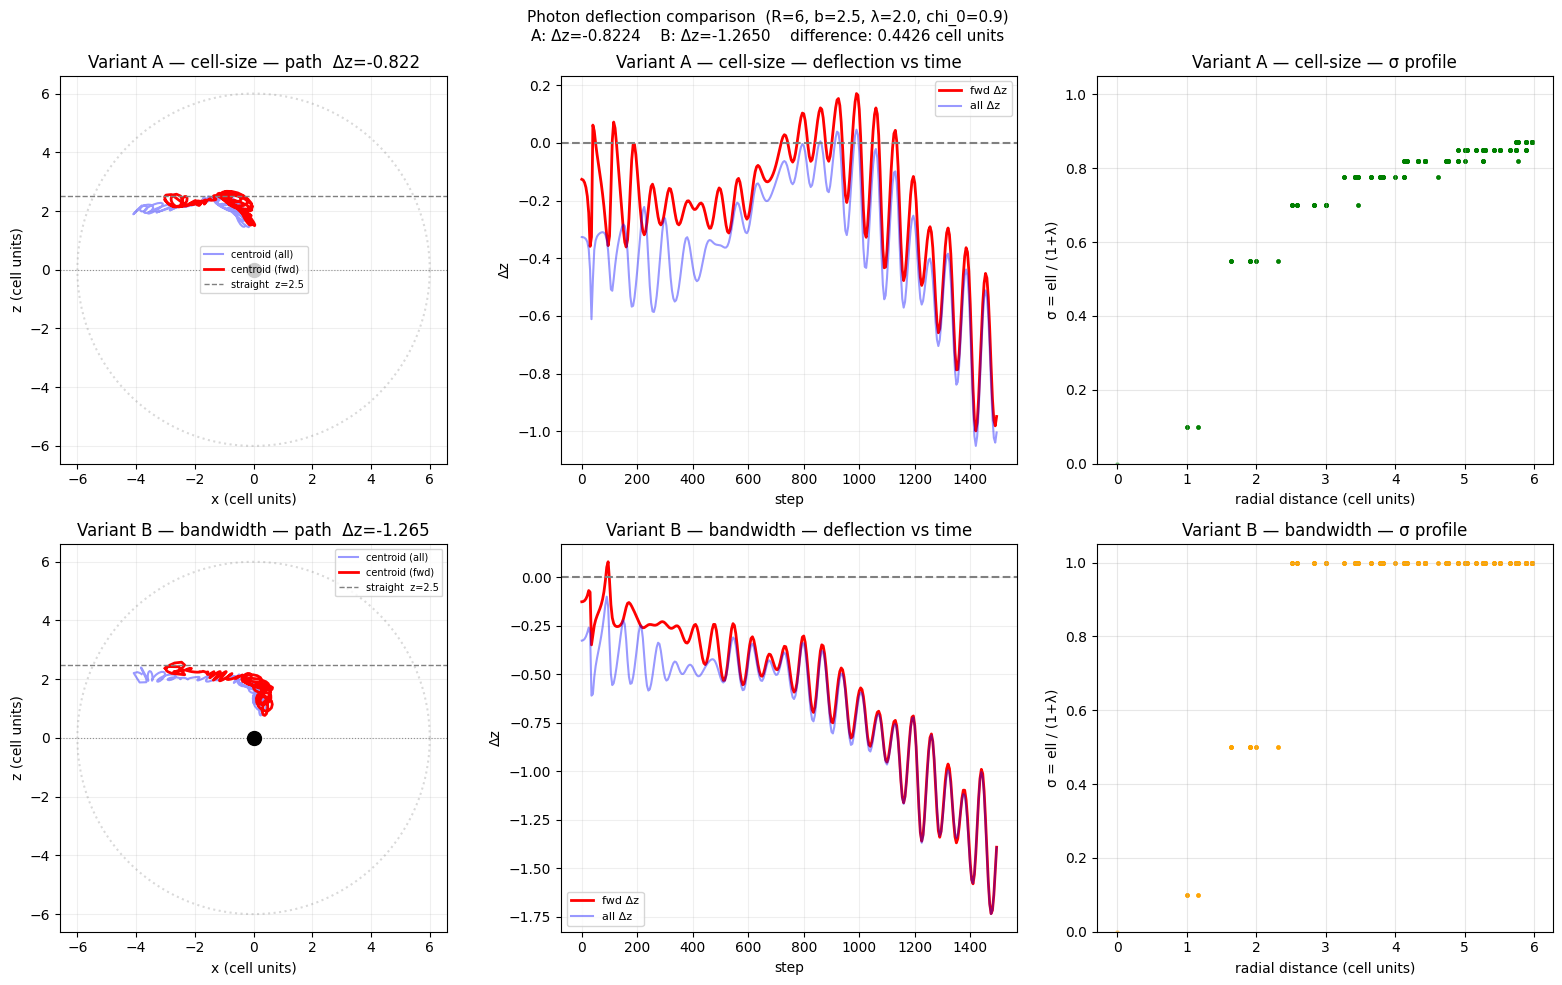

Saved photon_deflection_comparison.png


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
theta = np.linspace(0, 2 * np.pi, 300)

for row, (label, steps, all_p, fwd_p, dz, ell, lam_arr) in enumerate([
    ("A — cell-size",  steps_A, all_A, fwd_A, dz_A, lat_A.ell, lat_A.lam),
    ("B — bandwidth",  steps_B, all_B, fwd_B, dz_B, lat_B.ell, lat_B.lam),
]):
    # panel 1 — x-z path
    ax = axes[row, 0]
    ax.plot(all_p[:, 0], all_p[:, 2], "b-", alpha=0.4, lw=1.5, label="centroid (all)")
    ax.plot(fwd_p[:, 0], fwd_p[:, 2], "r-", lw=2,   label="centroid (fwd)")
    ax.axhline(B, color="gray", ls="--", lw=1, label=f"straight  z={B}")
    ax.axhline(0, color="k",    ls=":",  lw=0.8, alpha=0.4)
    ax.plot(R * np.cos(theta), R * np.sin(theta), "k:", alpha=0.15)
    ax.scatter([0], [0], c="k", s=100, zorder=5)
    ax.set_xlabel("x (cell units)")
    ax.set_ylabel("z (cell units)")
    ax.set_title(f"Variant {label} — path  Δz={dz:+.3f}")
    ax.legend(fontsize=7)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)

    # panel 2 — Δz vs step
    ax = axes[row, 1]
    ax.plot(steps, fwd_p[:, 2] - B, "r-", lw=2, label="fwd Δz")
    ax.plot(steps, all_p[:, 2] - B, "b-", alpha=0.4, lw=1.5, label="all Δz")
    ax.axhline(0, color="gray", ls="--")
    ax.set_xlabel("step")
    ax.set_ylabel("Δz")
    ax.set_title(f"Variant {label} — deflection vs time")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.2)

    # panel 3 — sigma profile
    ax = axes[row, 2]
    lat_ref = lat_A if row == 0 else lat_B
    r_rad = np.linalg.norm(lat_ref.pos, axis=1)
    sigma = ell / (1.0 + lam_arr.astype(float))
    order = np.argsort(r_rad)
    ax.scatter(r_rad[order], sigma[order], s=5, alpha=0.4,
               c=("green" if row == 0 else "orange"))
    ax.set_xlabel("radial distance (cell units)")
    ax.set_ylabel("σ = ell / (1+λ)")
    ax.set_title(f"Variant {label} — σ profile")
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    f"Photon deflection comparison  (R={R}, b={B}, λ={WAVELENGTH}, chi_0={CHI_0})\n"
    f"A: Δz={dz_A:+.4f}    B: Δz={dz_B:+.4f}    "
    f"difference: {abs(dz_A - dz_B):.4f} cell units",
    fontsize=11,
)
plt.tight_layout()
plt.savefig("photon_deflection_comparison.png", dpi=150)
plt.show()
print("Saved photon_deflection_comparison.png")

## Summary

In [6]:
print("=" * 50)
print(f"Variant A (cell-size)  Δz = {dz_A:+.4f} cell units")
print(f"Variant B (bandwidth)  Δz = {dz_B:+.4f} cell units")
print(f"Difference             |ΔΔz| = {abs(dz_A - dz_B):.4f} cell units")
print()
if abs(dz_A - dz_B) < 0.05 * max(abs(dz_A), abs(dz_B)):
    print("→ Mechanisms indistinguishable at this scale (same σ profile → same deflection).")
else:
    print("→ Mechanisms produce different deflections — σ profile alone does not determine the path.")
    print("  The field carrying σ (ell vs lam) has observable consequences.")

Variant A (cell-size)  Δz = -0.8224 cell units
Variant B (bandwidth)  Δz = -1.2650 cell units
Difference             |ΔΔz| = 0.4426 cell units

→ Mechanisms produce different deflections — σ profile alone does not determine the path.
  The field carrying σ (ell vs lam) has observable consequences.
